In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
from safepython import EET, sampling, util

In [111]:
def additive(x, y, z):
    return x + y

In [112]:
r = 1000
M = 3
lower = np.array([-1, -1, -1])
upper = np.array([ 1,  1,  1])
labels = ["x", "y", "z"]

X = sampling.OAT_sampling(r, M, distr_fun=sp.stats.uniform, distr_par=np.transpose([lower, upper - lower]).tolist(), samp_strat="lhs", des_type="trajectory")
Y = np.array([additive(*xs) for xs in X])

# mi, sigma, EE = EET.EET_indices(r, lower.tolist(), upper.tolist(), X, Y, design_type="trajectory")

In [113]:
dydx = np.zeros((r, 3))
x    = np.zeros((r, 3))
y    = np.zeros((r, 3))

for j in range(r):
    for i, label in enumerate(labels):
        k = j*4 + i

        x[j, i] = X[k, i]
        y[j, i] = Y[k]

        dx = (X[k + 1, i] - X[k, i])
        dy = (Y[k + 1] - Y[k])
        
        dydx[j, i] = dy/dx + np.random.normal(scale=0.1)
        
mi = np.array([sp.stats.bootstrap(np.atleast_2d(dydx[:, i]), np.mean, n_resamples=r) for i in range(len(labels))])
sd = np.array([sp.stats.bootstrap(np.atleast_2d(dydx[:, i]), np.std, n_resamples=r) for i in range(len(labels))])


mi_mean  = np.array([b.bootstrap_distribution.mean() for b in mi])
mi_lower = np.array([b.confidence_interval.low for b in mi])
mi_upper = np.array([b.confidence_interval.high for b in mi])

sd_mean  = np.array([b.bootstrap_distribution.mean() for b in sd])
sd_lower = np.array([b.confidence_interval.low for b in sd])
sd_upper = np.array([b.confidence_interval.high for b in sd])

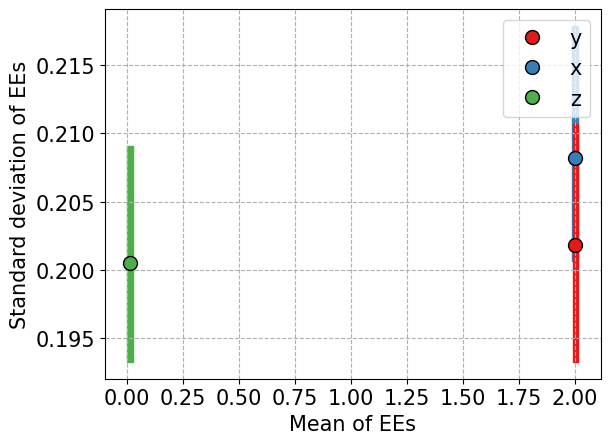

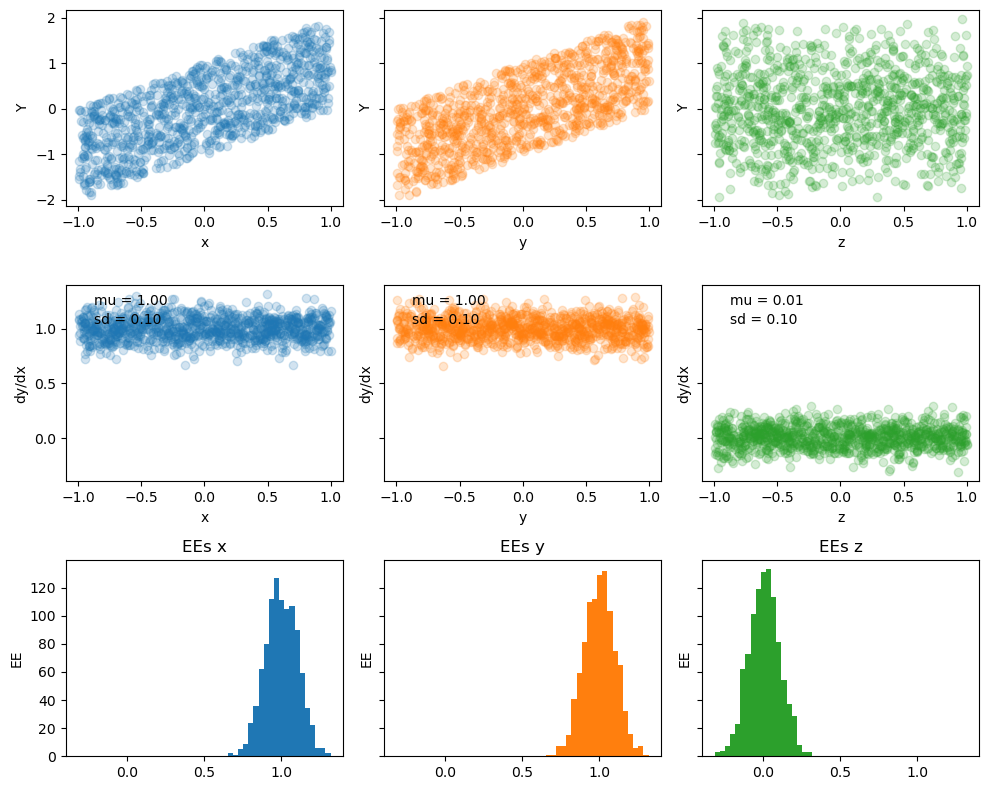

In [117]:
#[plt.scatter(mi_mean[i].round(10), sd_mean[i].round(10), label=labels[i], s=50, alpha=0.8) for i in range(3)]
#plt.gcf().legend(loc="outside center right")
#plt.xlabel("Mean of EEs")
#plt.ylabel("Std of EEs")

rgs = upper - lower
EET.EET_plot(mi_mean * rgs, sd_mean*rgs, labels, mi_lower*rgs, mi_upper*rgs, sd_lower*rgs, sd_upper*rgs)


fig, axs = plt.subplots(3, 3, figsize=(10, 8), sharey="row")

for i, label in enumerate(labels):
    color = f"C{i}"
    
    plt.sca(axs[0, i])
    #plt.scatter(X[:, i], Y, alpha=0.2)
    plt.scatter(x[:, i], y[:, i], color=color, alpha=0.2)
    plt.ylabel("Y")
    plt.xlabel(label)

    plt.sca(axs[1, i])
    plt.scatter(x[:, i], dydx[:, i], color=color, alpha=0.2)
    plt.text(0.1, 0.9, f"mu = {mi_mean[i]:.2f}", transform=plt.gca().transAxes)
    plt.text(0.1, 0.8, f"sd = {sd_mean[i]:.2f}", transform=plt.gca().transAxes)
    plt.xlabel(label)
    plt.ylabel("dy/dx")

    plt.sca(axs[2, i])
    plt.hist(dydx[:, i], bins=np.linspace(dydx.min(), dydx.max(), 50, endpoint=True), color=color)
    plt.title("EEs " + label)
    plt.ylabel("EE")
    
plt.tight_layout()